In [1]:
import time
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression, SGDRegressor
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score

Необходимые зависимости импортированы

Далее нужно подготовить данные

In [27]:
df = pd.read_csv('Life Expectancy Data.csv')

df = pd.get_dummies(df, drop_first=True)
df = df.fillna(df.median())

a = df.drop('Life expectancy ', axis=1)
x = a.drop('Year', axis=1)
y = df['Life expectancy ']

xtrain, xtest, ytrain, ytest = train_test_split(x, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
xtrain = scaler.fit_transform(xtrain)
xtest = scaler.transform(xtest)

print(xtrain.shape)

(2350, 211)


Файл датасета загружен, выполнено преобразование даных: get_dummies для перевода текстовых признаков в логический формат "является ли признаком А, признаком Б...", затем мы создаём y (параметр, который прогнозируем) и x (всё остальное). Затем производится приведение числовых признаков к общей размерности через Scaler. Также был удалён столбец Year, в котром записан год, для которого была справедлива статистика. Если этого не сделать, модель подумает, что год - это числовой показатель, и будет считать, что он влияет на продолжительность жизни.


Определение медианы y и выявление Accuracy

In [28]:
median_age = ytrain.median()
ytrain_class = (ytrain > median_age).astype(int)
ytest_class = (ytest > median_age).astype(int)

clf = LogisticRegression(max_iter = 1000, random_state = 42)
clf.fit(xtrain, ytrain_class)

sample_probs = clf.predict_proba(xtest[:5])[:,1]
sample_preds = clf.predict(xtest[:5])
display(
    pd.DataFrame(
        {
            "Вероятность (Сигмоида)":sample_probs,
            'Класс (Порог 0.5)':sample_preds,
            'Факт':ytest_class.iloc[:5].values
        }
    )
)

print(f'Точность классификации (Accuracy): {accuracy_score(ytest_class, clf.predict(xtest)):.4f}')

,Вероятность (Сигмоида),Класс (Порог 0.5),Факт
0,8.790182e-01,1,1
1,9.996200e-01,1,1
2,1.000000e+00,1,1
3,9.995721e-01,1,1
4,4.082016e-07,0,0


Точность классификации (Accuracy): 0.9252


В этом модуле мы определили медианное значение y, а также использвали его для проверки Acuracy.

Регрессия: MHK и SGD

In [29]:
start_ols = time.time()
ols = LinearRegression()
ols.fit(xtrain, ytrain)
time_ols = time.time()-start_ols
pred_ols = ols.predict(xtest)

start_sgd = time.time()
sgd = SGDRegressor(
    max_iter=1000, tol=1e-3, eta0=0.01, learning_rate='adaptive', random_state=42
)
sgd.fit(xtrain, ytrain)
time_sgd = time.time()-start_sgd
pred_sgd = time.time()-start_sgd
pred_sgd = sgd.predict(xtest)

rmse_ols = np.sqrt(mean_squared_error(ytest, pred_ols))
r2_ols = r2_score(ytest, pred_ols)

rmse_sgd = np.sqrt(mean_squared_error(ytest, pred_sgd))
r2_sgd = r2_score(ytest, pred_sgd)

print(f'MHK (Аналитический): RMSE = {rmse_ols:,.2f} | R2 = {r2_ols:,.2f} | Время = {time_ols:.5f} сек')
print(f'SGD (Итеративный): RMSE = {rmse_sgd:,.2f} | R2 = {r2_sgd:,.2f} | Время = {time_sgd:.5f} сек')

MHK (Аналитический): RMSE = 2.15 | R2 = 0.95 | Время = 0.03048 сек
SGD (Итеративный): RMSE = 6,877,359,389.21 | R2 = -545,742,587,211,081,472.00 | Время = 0.06185 сек


Здесь мы сравниваем точность разных методов предсказания: аналитического и итеративного. Видно, что показатели точности ближе к идеальным у аналитического метода. У него же меньше время выполнения.

Визуализация данных

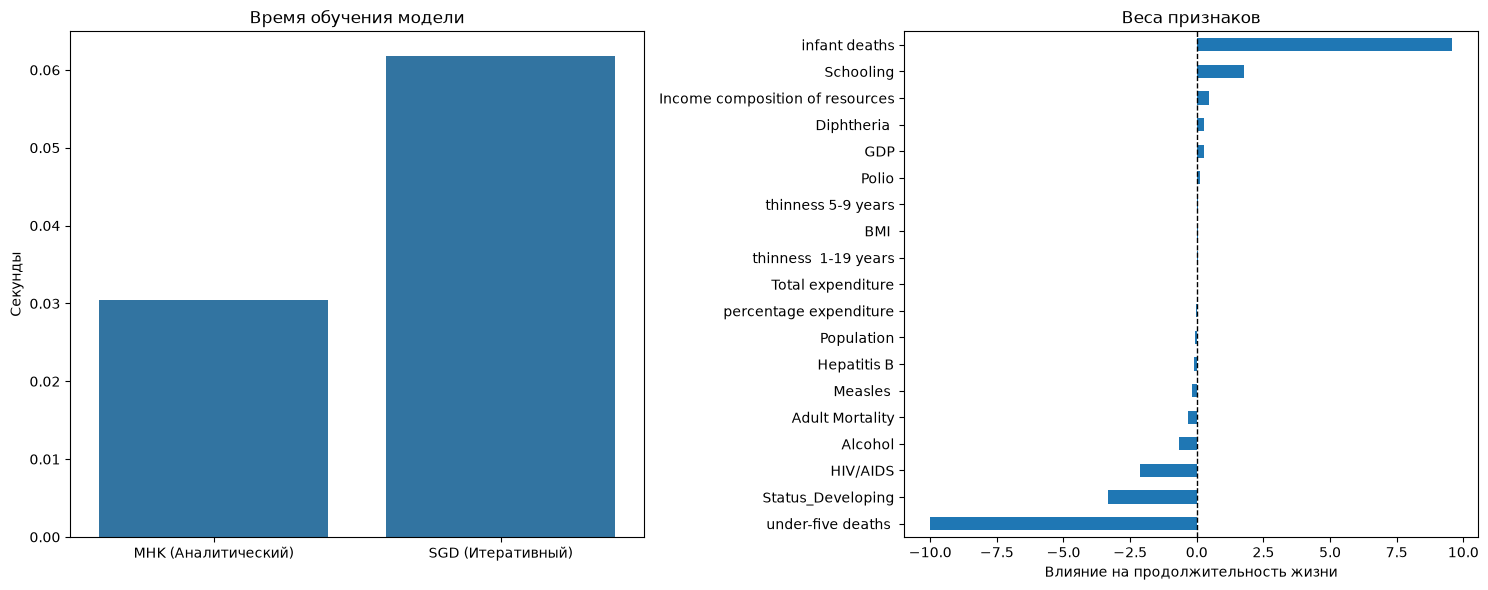

In [30]:
ig, axes = plt.subplots(1,2, figsize = (15,6))
#1. Сравнение времени выполнения
sns.barplot(
    x=["MHK (Аналитический)", 'SGD (Итеративный)'],
    y = [time_ols, time_sgd],
    ax = axes[0]
)

axes[0].set_title('Время обучения модели')
axes[0].set_ylabel('Секунды')

weights = pd.Series(ols.coef_, index=x.columns).sort_values()
#Строка, чтобы убрать признак страны и не перегружать график
weights = weights[~weights.index.str.contains('Country')].sort_values()

weights.plot(kind='barh', ax = axes[1])
axes[1].set_title('Веса признаков')
axes[1].set_xlabel('Влияние на продолжительность жизни')
axes[1].axvline(0, color='black', linestyle='--', lw=1)

plt.tight_layout()
plt.show()

Здесь строятся графики, отображающие разницу во времени выполнения между разными методами предсказания и влияние конкретных признаков на продолжительность жзни. Видно, что аналитический метод выполняется примерно в два раза быстрее. Признак, наиболее сильно сокращающий продолжительность жизни - смертность в возрасте до 5 лет, при этом показателем, сильнее всего повышающим продолжительность жизни, оказалась младенческая смертность (возможно, из-за ошибки модели, либо продолжительность жизни младенцев не учитывалась вместе с общей в оригинальном датасете). В остальном показатели распределены логично: продолжительность жизни сильнее всего сокращают статус страны "развивающаяся", ВИЧ/СПИД и алкоголь. Сильнее всего повышают продолжительность жизни образование, доход и вакцинация от дифтерии.